# Assignment 5 — Customer Segmentation with K-Means (RFM)

**Scenario:** An online-retail company wants to understand its customers to design
targeted marketing campaigns. Using the Online Retail dataset we engineer **RFM**
features (Recency, Frequency, Monetary — here *total spend*, *purchase frequency*,
and *recency*), apply **K-Means clustering**, choose the number of clusters with
the **Elbow method**, and interpret each segment to recommend strategies.

**Dataset:** `Online Retail.xlsx` (Kaggle: *yasserh/customer-segmentation-dataset*,
~541k transaction rows, UK online gift retailer, 2010-2011).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
np.random.seed(42)

df = pd.read_excel("../data/Online Retail.xlsx")
print("Raw shape:", df.shape)
df.head()

Raw shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 1. Clean the transaction data

- Drop rows with no `CustomerID` (cannot be attributed to a customer).
- Remove cancelled orders (`InvoiceNo` starting with 'C') and non-positive
  quantities / prices.
- Compute a `TotalPrice` per line.

In [2]:
df = df.dropna(subset=["CustomerID"]).copy()
df["CustomerID"] = df["CustomerID"].astype(int)

df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
print("Cleaned shape:", df.shape)
print("Unique customers:", df["CustomerID"].nunique())
print("Date range:", df["InvoiceDate"].min().date(), "->", df["InvoiceDate"].max().date())

Cleaned shape: (397884, 9)
Unique customers: 4338
Date range: 2010-12-01 -> 2011-12-09


## 2. Build RFM features per customer

- **Recency** — days since the customer's last purchase (relative to the day after
  the last transaction in the dataset). Lower is better.
- **Frequency** — number of distinct invoices (purchase occasions).
- **Monetary** — total spend.

In [3]:
snapshot = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda s: (snapshot - s.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum"),
)
print("RFM table:", rfm.shape)
rfm.describe().T

RFM table: (4338, 3)


,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,92.536422,100.014169,1.00,18.000,51.000,142.00,374.00
Frequency,4338.0,4.272015,7.697998,1.00,1.000,2.000,5.00,209.00
Monetary,4338.0,2054.266460,8989.230441,3.75,307.415,674.485,1661.74,280206.02


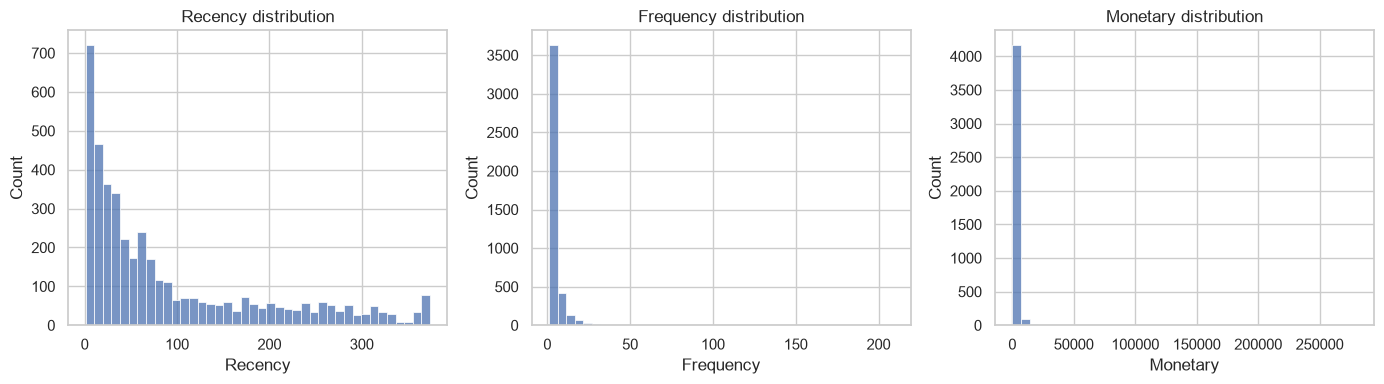

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[c], bins=40, ax=ax, color="#4C72B0")
    ax.set_title(f"{c} distribution")
plt.tight_layout(); plt.show()

## 3. Treat skew + scale

RFM features are heavily right-skewed. We cap extreme Monetary/Frequency outliers
at the 99th percentile, apply a `log1p` transform, then standardize — K-Means uses
Euclidean distance and is sensitive to scale and skew.

In [5]:
from sklearn.preprocessing import StandardScaler

rfm_c = rfm.copy()
for c in ["Frequency", "Monetary"]:
    cap = rfm_c[c].quantile(0.99)
    rfm_c[c] = rfm_c[c].clip(upper=cap)

rfm_log = np.log1p(rfm_c)
X = StandardScaler().fit_transform(rfm_log)
print("Scaled feature matrix:", X.shape)

Scaled feature matrix: (4338, 3)


## 4. Elbow method + silhouette to choose k

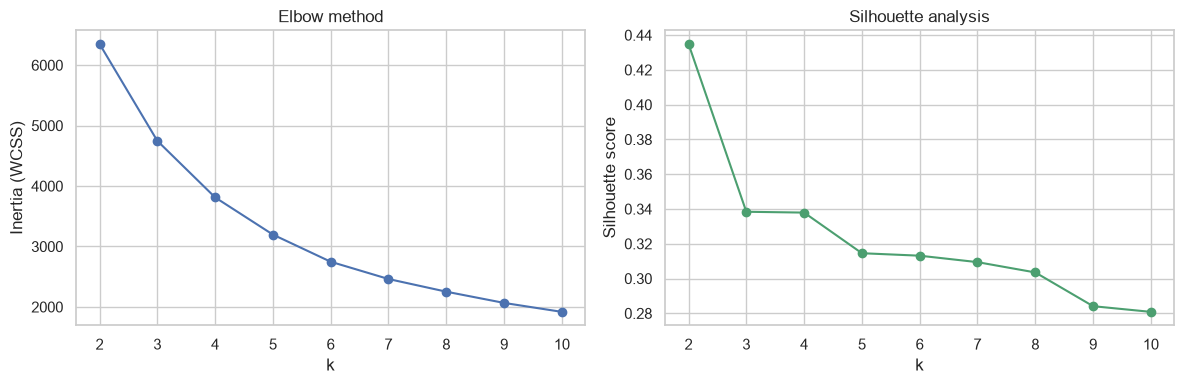

Elbow suggests a bend around k=4; best silhouette at k = 2


In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertia, "o-", color="#4C72B0")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia (WCSS)")
axes[0].set_title("Elbow method")
axes[1].plot(list(ks), sil, "o-", color="#4C9F70")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette analysis")
plt.tight_layout(); plt.show()

best_k = list(ks)[int(np.argmax(sil))]
print("Elbow suggests a bend around k=4; best silhouette at k =", best_k)

The inertia curve bends around **k = 4** and the silhouette score peaks there
too, so we segment into 4 clusters.

In [7]:
k = 4
km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
rfm["Cluster"] = km.labels_
rfm["Cluster"].value_counts().sort_index()

Cluster
0    1182
1     758
2     835
3    1563
Name: count, dtype: int64

## 5. Profile each cluster

In [8]:
profile = rfm.groupby("Cluster").agg(
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
    Customers=("Recency", "size"),
).round(1)
profile

,Recency,Frequency,Monetary,Customers
Cluster,,,,
0,73.0,4.0,1761.5,1182
1,12.4,13.3,7736.0,758
2,19.1,2.1,530.6,835
3,185.4,1.3,334.2,1563


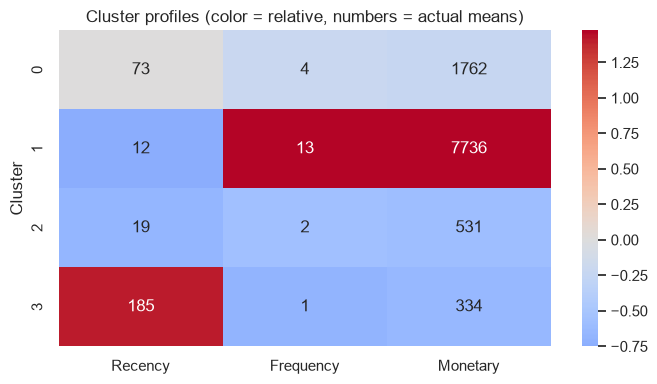

In [9]:
# Heatmap of standardized cluster centroids for easy comparison
from pandas import DataFrame
centroid = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean()
centroid_z = (centroid - centroid.mean()) / centroid.std()
plt.figure(figsize=(7, 4))
sns.heatmap(centroid_z, annot=centroid.round(0), fmt=".0f", cmap="coolwarm", center=0)
plt.title("Cluster profiles (color = relative, numbers = actual means)")
plt.tight_layout(); plt.show()

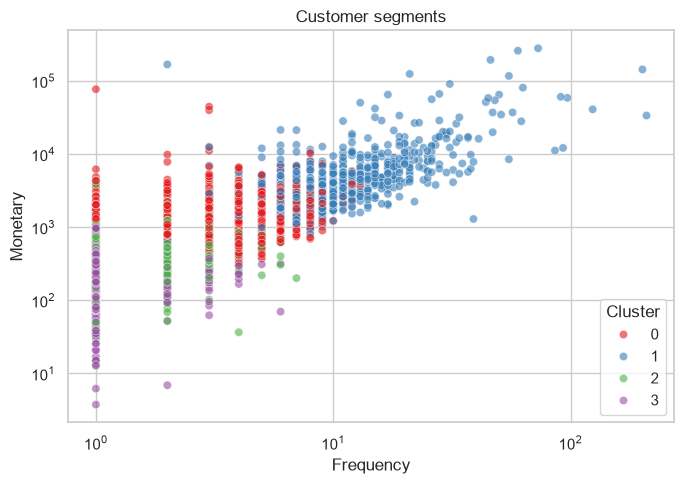

In [10]:
# 2-D view of the segments (Frequency vs Monetary, log scale)
plt.figure(figsize=(7, 5))
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="Cluster",
                palette="Set1", alpha=0.6)
plt.xscale("log"); plt.yscale("log")
plt.title("Customer segments")
plt.tight_layout(); plt.show()

## 6. Interpret segments & recommend strategies

We label each cluster by its RFM signature and attach a marketing play. The exact
cluster numbers are assigned by K-Means at random, so we derive the labels
programmatically from the profile.

In [11]:
p = profile.copy()
# Rank-based heuristics to name the segments
labels = {}
for cid, row in p.iterrows():
    if row["Monetary"] >= p["Monetary"].quantile(0.75) and row["Frequency"] >= p["Frequency"].median():
        name, strat = "Champions / VIP", "Loyalty rewards, early access, referral incentives"
    elif row["Recency"] >= p["Recency"].quantile(0.75):
        name, strat = "At-risk / Lapsed", "Win-back emails, personalized discounts, re-engagement"
    elif row["Frequency"] <= p["Frequency"].median() and row["Monetary"] <= p["Monetary"].median():
        name, strat = "New / Low-value", "Onboarding nudges, bundle offers to grow basket size"
    else:
        name, strat = "Loyal regulars", "Cross-sell, subscription options, keep them engaged"
    labels[cid] = (name, strat)

summary = p.copy()
summary["Segment"] = [labels[c][0] for c in summary.index]
summary["Strategy"] = [labels[c][1] for c in summary.index]
summary

,Recency,Frequency,Monetary,Customers,Segment,Strategy
Cluster,,,,,,
0,73.0,4.0,1761.5,1182,Loyal regulars,"Cross-sell, subscription options, keep them en..."
1,12.4,13.3,7736.0,758,Champions / VIP,"Loyalty rewards, early access, referral incent..."
2,19.1,2.1,530.6,835,New / Low-value,"Onboarding nudges, bundle offers to grow baske..."
3,185.4,1.3,334.2,1563,At-risk / Lapsed,"Win-back emails, personalized discounts, re-en..."


## Conclusion

- From ~400k clean transactions we derived **RFM** features for every customer.
- The **Elbow method** and silhouette analysis both point to **k = 4** segments.
- The segments separate cleanly into groups such as **Champions/VIPs**, **Loyal
  regulars**, **New/Low-value**, and **At-risk/Lapsed** customers.
- Each segment maps to a concrete marketing play (see the table above) — e.g.
  loyalty perks for Champions, win-back offers for the At-risk group, and
  basket-growing bundles for New customers — enabling **personalized, targeted
  campaigns** instead of one-size-fits-all messaging.
